# IEEE-CIS Fraud Detection
## 1. Особенности данных

[Датасет](https://www.kaggle.com/competitions/ieee-fraud-detection/data)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML, display

DATA_DIR = Path("data")

In [2]:
transactions = pd.read_csv(DATA_DIR / "train_transaction.csv")
identity = pd.read_csv(DATA_DIR / "train_identity.csv")
df = transactions.merge(identity, on="TransactionID", how="left", validate="one_to_one")

### 1.1. Основные статистики

По описанию авторов категориальные признаки: `ProductCD`, `card1`–`card6`, `addr1`, `addr2`,
`P_emaildomain`, `R_emaildomain`, `M1`–`M9`, `DeviceType`, `DeviceInfo`, `id_12`–`id_38`.

In [3]:
categorical_columns = (
    ["ProductCD", "addr1", "addr2", "P_emaildomain", "R_emaildomain", "DeviceType", "DeviceInfo"]
    + [f"card{i}" for i in range(1, 7)]
    + [f"M{i}" for i in range(1, 10)]
    + [f"id_{i:02}" for i in range(12, 39)]
)
df[categorical_columns] = df[categorical_columns].astype("category")

feature_columns = df.columns.drop(["TransactionID", "isFraud"]).tolist()
numeric_columns = [c for c in feature_columns if c not in categorical_columns]

In [4]:
description = df.describe(include="all").T

display(HTML(description.to_html()))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
TransactionID,590540.0,NaN,NaN,NaN,3282269.5,170474.358321,2987000.0,3134634.75,3282269.5,3429904.25,3577539.0
isFraud,590540.0,NaN,NaN,NaN,0.03499,0.183755,0.0,0.0,0.0,0.0,1.0
TransactionDT,590540.0,NaN,NaN,NaN,7372311.310116,4617223.64654,86400.0,3027057.75,7306527.5,11246620.0,15811131.0
TransactionAmt,590540.0,NaN,NaN,NaN,135.027176,239.162522,0.251,43.321,68.769,125.0,31937.391
ProductCD,590540,5,W,439670,NaN,NaN,NaN,NaN,NaN,NaN,NaN
card1,590540.0,13553.0,7919.0,14932.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
card2,581607.0,500.0,321.0,48935.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
card3,588975.0,114.0,150.0,521287.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
card4,588963,4,visa,384767,NaN,NaN,NaN,NaN,NaN,NaN,NaN
card5,586281.0,119.0,226.0,296546.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.2. Пропущенные значения

Доля пропусков признака считается от числа транзакций, общая доля — от ячеек
всех 432 признаков.

In [5]:
missing = df[feature_columns].isna()
missing_per_row = missing.sum(axis=1)
missing_by_feature = pd.DataFrame({
    "Пропусков": missing.sum(),
    "Доля, %": missing.mean() * 100,
}).sort_values("Доля, %", ascending=False)

display(HTML(missing_by_feature.to_html()))

display(pd.Series({
    "Пустых ячеек": missing_per_row.sum(),
    "Всего ячеек": len(df) * len(feature_columns),
    "Пустых ячеек, %": round(missing_per_row.sum() / missing.size * 100, 2),
    "Строк без пропусков": missing_per_row.eq(0).sum(),
    "Признаков с пропусками": missing_by_feature["Пропусков"].gt(0).sum(),
    "Признаков с >50% пропусков": missing_by_feature["Доля, %"].gt(50).sum(),
    "Признаков с >90% пропусков": missing_by_feature["Доля, %"].gt(90).sum(),
}, dtype=object).to_frame("Значение"))

,Пропусков,"Доля, %"
id_24,585793,99.196159
id_25,585408,99.130965
id_08,585385,99.127070
id_07,585385,99.127070
id_21,585381,99.126393
id_26,585377,99.125715
id_27,585371,99.124699
id_23,585371,99.124699
id_22,585371,99.124699
dist2,552913,93.628374


,Значение
Пустых ячеек,115523073
Всего ячеек,255113280
"Пустых ячеек, %",45.28
Строк без пропусков,0
Признаков с пропусками,414
Признаков с >50% пропусков,214
Признаков с >90% пропусков,12


Пропущено 45,28% ячеек признаков; строк без пропусков нет. Поэтому удаление всех неполных строк оставило бы пустую выборку.

У многих признаков совпадает количество пропусков. Проверим, совпадают ли и сами множества строк, и объединим такие признаки в группы.

In [6]:
pattern_groups = {}

for column in feature_columns:
    if missing[column].any():
        pattern = missing[column].to_numpy().tobytes()
        pattern_groups.setdefault(pattern, []).append(column)

missing_groups = list(pattern_groups.values())

In [7]:
group_summary = pd.DataFrame([
    {
        "Пропуски, %": missing[columns[0]].mean() * 100,
        "Число признаков": len(columns),
        "Признаки": ", ".join(columns),
    }
    for columns in missing_groups if len(columns) > 1
]).sort_values("Пропуски, %", ascending=False)

display(HTML(group_summary.to_html(index=False)))

"Пропуски, %",Число признаков,Признаки
99.127070,2,"id_07, id_08"
99.124699,3,"id_22, id_23, id_27"
88.768923,2,"id_03, id_04"
87.312290,4,"D8, D9, id_09, id_10"
86.123717,18,"V138, V139, V140, V141, V142, V146, V147, V148, V149, V153, V154, V155, V156, V157, V158, V161, V162, V163"
86.122701,11,"V143, V144, V145, V150, V151, V152, V159, V160, V164, V165, V166"
86.054967,18,"V322, V323, V324, V325, V326, V327, V328, V329, V330, V331, V332, V333, V334, V335, V336, V337, V338, V339"
77.913435,46,"V217, V218, V219, V223, V224, V225, V226, V228, V229, V230, V231, V232, V233, V235, V236, V237, V240, V241, V242, V243, V244, V246, V247, V248, V249, V252, V253, V254, V257, V258, V260, V261, V262, V263, V264, V265, V266, V267, V268, V269, V273, V274, V275, V276, V277, V278"
76.823755,2,"id_05, id_06"
76.355370,31,"V167, V168, V172, V173, V176, V177, V178, V179, V181, V182, V183, V186, V187, V190, V191, V192, V193, V196, V199, V202, V203, V204, V205, V206, V207, V211, V212, V213, V214, V215, V216"


Теперь посмотрим зависимость доли пропусков от типа продукта `ProductCD`. На графике отобразим все найденные группы — по одному признаку от каждой группы с одинаковыми пропусками.

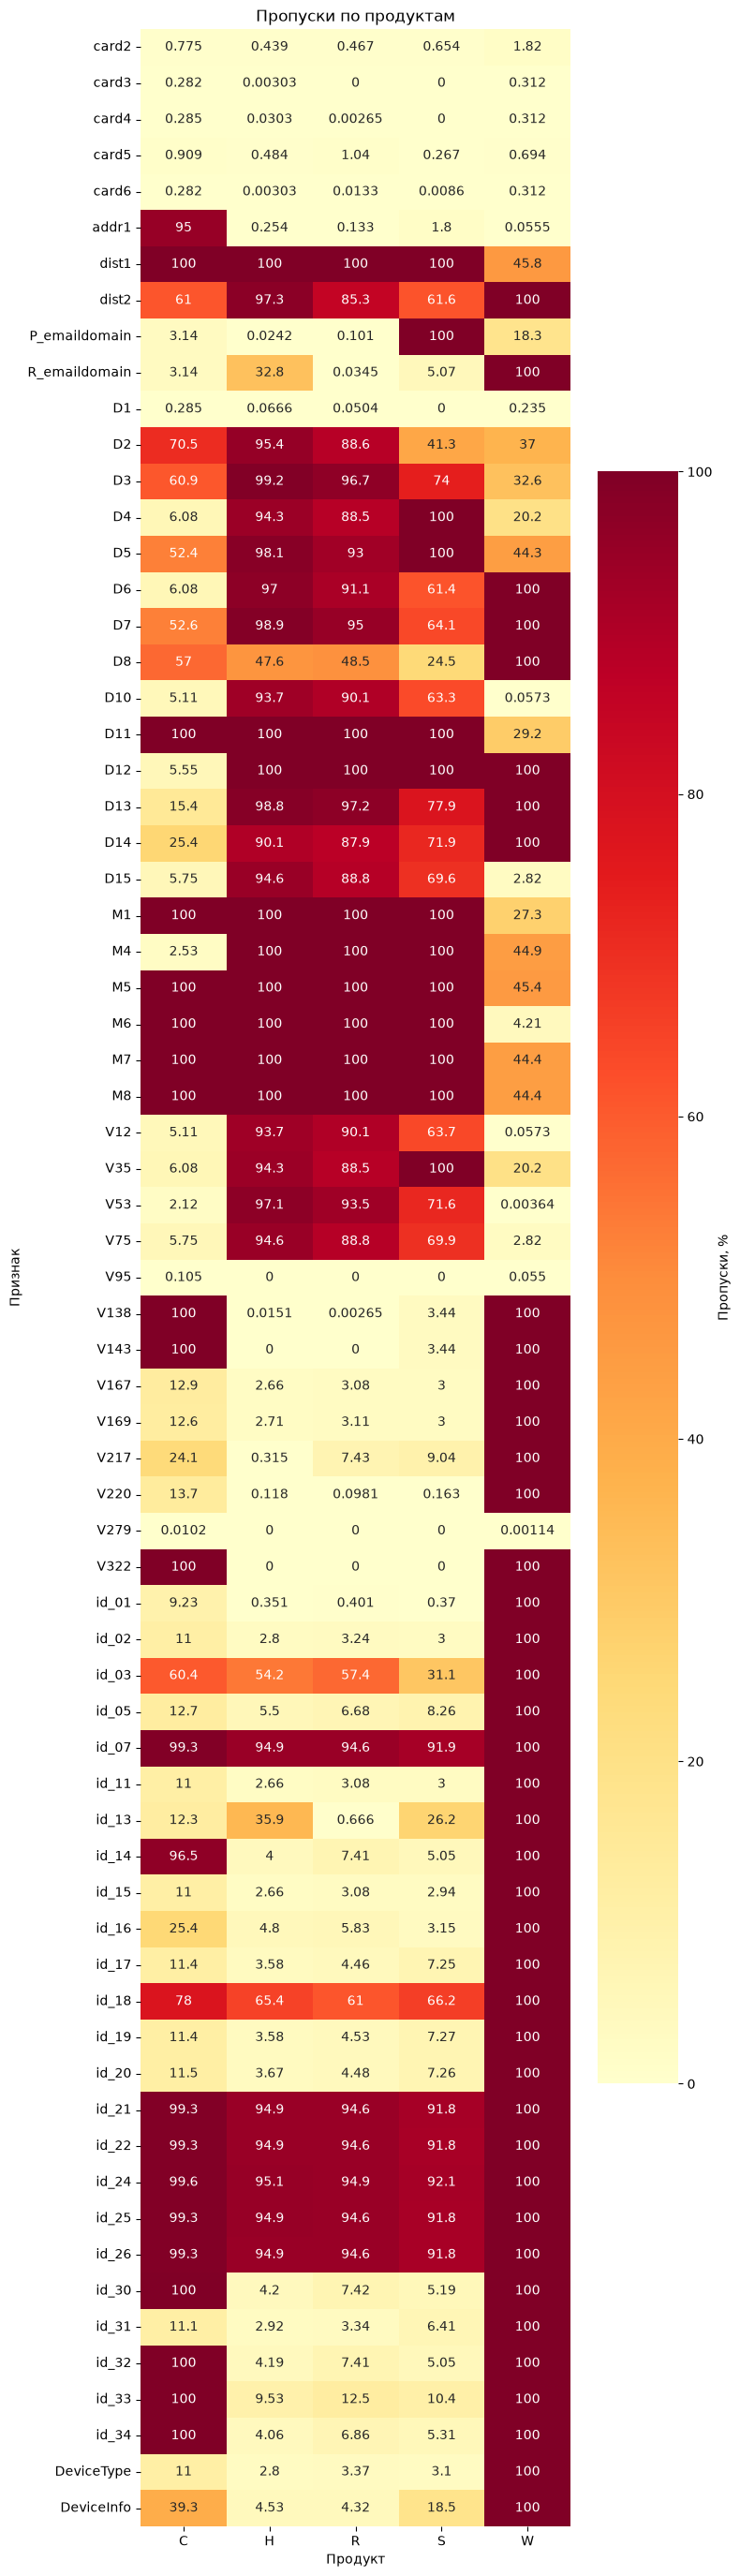

In [8]:
group_columns = [columns[0] for columns in missing_groups]
missing_by_product = (
    missing[group_columns]
    .groupby(df["ProductCD"], observed=True)
    .mean().T * 100
)

fig, ax = plt.subplots(figsize=(8, max(4, len(missing_by_product) * 0.4)))
sns.heatmap(
    missing_by_product,
    annot=True,
    fmt=".3g",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Пропуски, %"},
    ax=ax,
)
ax.set(
    title="Пропуски по продуктам",
    xlabel="Продукт",
    ylabel="Признак",
)
plt.tight_layout()
plt.show()

Сравним количество и долю транзакций каждого продукта отдельно в `train` и `test`.

In [9]:
test_transactions = pd.read_csv(DATA_DIR / "test_transaction.csv")
test_identity = pd.read_csv(DATA_DIR / "test_identity.csv")
test_identity.columns = test_identity.columns.str.replace("id-", "id_", regex=False)

test_df = test_transactions.merge(
    test_identity, on="TransactionID", how="left", validate="one_to_one"
)
assert set(test_df.columns) == set(feature_columns + ["TransactionID"])

test_size = len(test_df)
assert not test_df[numeric_columns].le(-10000).any().any()
test_product_counts = test_df["ProductCD"].value_counts(dropna=False)
display(pd.Series({"Train": len(df), "Test": test_size}, name="Транзакций").to_frame())

del test_transactions, test_identity, test_df

,Транзакций
Train,590540
Test,506691


,Train: транзакций,Train: %,Test: транзакций,Test: %
ProductCD,,,,
W,439670,74.452196,360987,71.244013
C,68519,11.602770,69266,13.670265
R,37699,6.383818,35647,7.035254
H,33024,5.592170,29373,5.797024
S,11628,1.969045,11418,2.253444


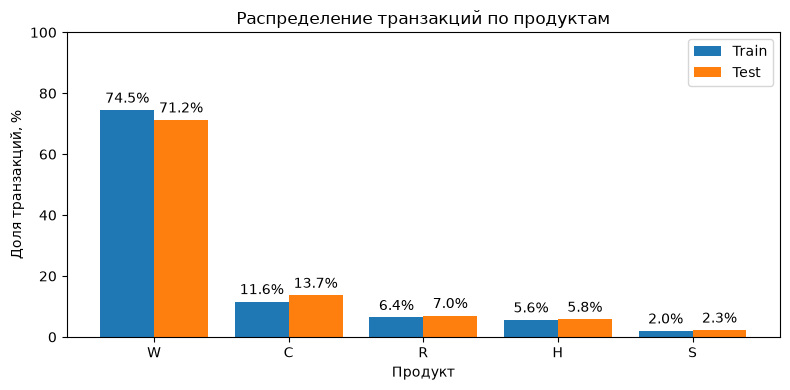

In [10]:
train_product_counts = df["ProductCD"].value_counts(dropna=False)
product_counts = pd.DataFrame({
    "Train: транзакций": train_product_counts,
    "Train: %": train_product_counts / len(df) * 100,
    "Test: транзакций": test_product_counts,
    "Test: %": test_product_counts / test_size * 100,
}).fillna(0).sort_values("Train: %", ascending=False)
display(product_counts)

ax = product_counts[["Train: %", "Test: %"]].plot.bar(figsize=(8, 4), rot=0, width=0.8)
ax.set(
    title="Распределение транзакций по продуктам",
    xlabel="Продукт",
    ylabel="Доля транзакций, %",
    ylim=(0, 100),
)
ax.legend(["Train", "Test"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
plt.tight_layout()
plt.show()

Доля пропусков в некоторых признаках сильно зависит от продукта, особенно выделяется, что признаки из таблицы `identity` полностью отсутствуют у продукта `W`. Возможно, для разных продуктов собирают разный набор сведений, поэтому часть пропусков связана с особенностями сбора данных.

При этом доли разных продуктов в `train` и `test` примерно совпадают.

Теперь сравним пропуски у обычных и мошеннических транзакций. Классы имеют разные размеры, поэтому будем смотреть в первую очередь на долю.

In [11]:
class_sizes = df.groupby("isFraud").size()
display(class_sizes.to_frame("Транзакций"))

missing_counts = missing.groupby(df["isFraud"]).sum().T
missing_shares = missing_counts.div(class_sizes, axis="columns") * 100

missing_by_target = pd.DataFrame({
    "Обычные: пропусков": missing_counts[0],
    "Обычные: %": missing_shares[0],
    "Фрод: пропусков": missing_counts[1],
    "Фрод: %": missing_shares[1],
    "Разница, п.п.": missing_shares[1] - missing_shares[0],
}).sort_values("Разница, п.п.", ascending=False)

display(HTML(missing_by_target.to_html()))

,Транзакций
isFraud,
0,569877
1,20663


,Обычные: пропусков,Обычные: %,Фрод: пропусков,Фрод: %,"Разница, п.п."
M6,157389,27.618065,11971,57.934472,30.316407
addr1,57965,10.171493,7741,37.463098,27.291605
addr2,57965,10.171493,7741,37.463098,27.291605
M1,256779,45.058671,14321,69.307458,24.248787
M2,256779,45.058671,14321,69.307458,24.248787
M3,256779,45.058671,14321,69.307458,24.248787
V9,264730,46.453884,14557,70.449596,23.995712
V1,264730,46.453884,14557,70.449596,23.995712
V2,264730,46.453884,14557,70.449596,23.995712
V3,264730,46.453884,14557,70.449596,23.995712


Доли пропусков различаются между классами: например, `addr1` отсутствует у 10,17% обычных и 37,46% мошеннических транзакций. Поэтому сам факт пропуска может быть полезен для предсказания.

В категориальных признаках заменим пропуски на отдельную категорию `__MISSING__`.

Числовые NaN заменим на `-10000`: все известные числовые значения `train` и `test` больше этого числа. Для линейной регрессии такая заглушка не подойдёт и придётся подставлять какое-то другое число (например, среднее или медиану), но другие модели (например, решающие деревья) смогут отделить это значение.

In [12]:
df_prepared = df.copy()
df_prepared[categorical_columns] = (
    df[categorical_columns]
    .astype("string")
    .fillna("__MISSING__")
    .astype("category")
)

assert not df[numeric_columns].le(-10000).any().any()
df_prepared.loc[:, numeric_columns] = df[numeric_columns].fillna(-10000)

display(HTML(df_prepared.head().to_html()))

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12,D13,D14,D15,M1,M2,M3,M4,M5,M6,M7,M8,M9,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,V29,V30,V31,V32,V33,V34,V35,V36,V37,V38,V39,V40,V41,V42,V43,V44,V45,V46,V47,V48,V49,V50,V51,V52,V53,V54,V55,V56,V57,V58,V59,V60,V61,V62,V63,V64,V65,V66,V67,V68,V69,V70,V71,V72,V73,V74,V75,V76,V77,V78,V79,V80,V81,V82,V83,V84,V85,V86,V87,V88,V89,V90,V91,V92,V93,V94,V95,V96,V97,V98,V99,V100,V101,V102,V103,V104,V105,V106,V107,V108,V109,V110,V111,V112,V113,V114,V115,V116,V117,V118,V119,V120,V121,V122,V123,V124,V125,V126,V127,V128,V129,V130,V131,V132,V133,V134,V135,V136,V137,V138,V139,V140,V141,V142,V143,V144,V145,V146,V147,V148,V149,V150,V151,V152,V153,V154,V155,V156,V157,V158,V159,V160,V161,V162,V163,V164,V165,V166,V167,V168,V169,V170,V171,V172,V173,V174,V175,V176,V177,V178,V179,V180,V181,V182,V183,V184,V185,V186,V187,V188,V189,V190,V191,V192,V193,V194,V195,V196,V197,V198,V199,V200,V201,V202,V203,V204,V205,V206,V207,V208,V209,V210,V211,V212,V213,V214,V215,V216,V217,V218,V219,V220,V221,V222,V223,V224,V225,V226,V227,V228,V229,V230,V231,V232,V233,V234,V235,V236,V237,V238,V239,V240,V241,V242,V243,V244,V245,V246,V247,V248,V249,V250,V251,V252,V253,V254,V255,V256,V257,V258,V259,V260,V261,V262,V263,V264,V265,V266,V267,V268,V269,V270,V271,V272,V273,V274,V275,V276,V277,V278,V279,V280,V281,V282,V283,V284,V285,V286,V287,V288,V289,V290,V291,V292,V293,V294,V295,V296,V297,V298,V299,V300,V301,V302,V303,V304,V305,V306,V307,V308,V309,V310,V311,V312,V313,V314,V315,V316,V317,V318,V319,V320,V321,V322,V323,V324,V325,V326,V327,V328,V329,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,id_10,id_11,id_12,id_13,id_14,id_15,id_16,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,__MISSING__,150.0,discover,142.0,credit,315.0,87.0,19.0,-10000.0,__MISSING__,__MISSING__,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,2.0,0.0,1.0,1.0,14.0,-10000.0,13.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,13.0,13.0,-10000.0,-10000.0,-10000.0,0.0,T,T,T,M2,F,T,__MISSING__,__MISSING__,__MISSING__,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,117.0,0.0,0.0,0.0,0.0,0.0,117.0,0.0,0.0,0.0,0.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.000000,-10000.000000,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000.0,-10000

### 1.3. Ошибочные значения

Точный смысл большинства признаков скрыт, поэтому мы можем проверить только часть значений. Проверим наличие `TransactionID`, соответствие ID из `identity` таблице транзакций и значения таргета `isFraud` (0 или 1). Для суммы платежа ожидаем положительные значения, для относительного времени — неотрицательные; пропусков в этих полях быть не должно.

`dist1` и `dist2` — расстояния, поэтому проверим их неотрицательность. `C1`–`C14` — счётчики: проверим, что известные значения целые и неотрицательные. Также проверим все числовые признаки на бесконечные значения.

In [13]:
invalid_identity_id = (
    identity["TransactionID"].isna()
    | ~identity["TransactionID"].isin(transactions["TransactionID"])
)
invalid_amount = df["TransactionAmt"].isna() | df["TransactionAmt"].le(0)
invalid_time = df["TransactionDT"].isna() | df["TransactionDT"].lt(0)

counter_columns = [f"C{i}" for i in range(1, 15)]
counter_values = df[counter_columns]
invalid_counters = counter_values.notna() & (
    counter_values.lt(0) | counter_values.ne(np.floor(counter_values))
)

quality_checks = pd.Series({
    "Некорректный TransactionID": transactions["TransactionID"].isna().sum(),
    "Некорректный ID в identity": invalid_identity_id.sum(),
    "Некорректный isFraud": (~df["isFraud"].isin([0, 1])).sum(),
    "Некорректный TransactionAmt": invalid_amount.sum(),
    "Некорректный TransactionDT": invalid_time.sum(),
    "Некорректный dist1": df["dist1"].lt(0).sum(),
    "Некорректный dist2": df["dist2"].lt(0).sum(),
    "Некорректные C1–C14": invalid_counters.any(axis=1).sum(),
    "Бесконечные числовые признаки": np.isinf(df[numeric_columns]).any(axis=1).sum(),
})
display(quality_checks.to_frame("Количество строк"))

,Количество строк
Некорректный TransactionID,0
Некорректный ID в identity,0
Некорректный isFraud,0
Некорректный TransactionAmt,0
Некорректный TransactionDT,0
Некорректный dist1,0
Некорректный dist2,0
Некорректные C1–C14,0
Бесконечные числовые признаки,0


Ошибочных значений не нашлось.

### 1.4. Выбросы

Проверим стандартные границы `[Q1 − 1,5·IQR; Q3 + 1,5·IQR]`, где `IQR = Q3 − Q1`. Также отдельно посмотрим на признаки с `IQR = 0`.

In [14]:
q1 = df[numeric_columns].quantile(0.25)
q3 = df[numeric_columns].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outside_iqr = (
    df[numeric_columns].lt(lower_bound)
    | df[numeric_columns].gt(upper_bound)
)
outlier_stats = pd.DataFrame({
    "IQR": iqr,
    "Нижняя граница": lower_bound,
    "Верхняя граница": upper_bound,
    "За границами": outside_iqr.sum(),
    "Доля среди заполненных, %": outside_iqr.sum() / df[numeric_columns].count() * 100,
}).sort_values("Доля среди заполненных, %", ascending=False)

display(outlier_stats.loc[outlier_stats["IQR"].gt(0)].head(15))
display(pd.Series({"Числовых признаков с IQR = 0": iqr.eq(0).sum()}))

,IQR,Нижняя граница,Верхняя граница,За границами,"Доля среди заполненных, %"
D14,2.000000,-3.000000,5.000000,14544,23.387525
id_05,1.000000,-1.500000,2.500000,30306,22.142988
D12,13.000000,-19.500000,32.500000,13749,21.244804
V332,25.000000,-37.500000,62.500000,17297,21.003995
D6,40.000000,-60.000000,100.000000,14828,20.260429
V204,20.000000,-30.000000,50.000000,26815,19.204188
V265,20.897525,-31.346288,52.243813,24839,19.043932
D7,17.000000,-25.500000,42.500000,7177,18.441812
V203,30.924400,-46.386600,77.311001,25709,18.412100
V264,33.593498,-50.390247,83.983746,23470,17.994326


Числовых признаков с IQR = 0    302
dtype: int64

У 302 из 383 числовых признаков `IQR` равен нулю, поэтому для них особо не имеет смысла смотреть на попадание в интервал.

Для остальных признаков выход за границы IQR тоже не доказывает ошибку: мы не знаем значения признаков и есть много транзакций со значениями за пределами интервала.

Рассмотрим сумму транзакции.

In [15]:
display(df["TransactionAmt"].quantile(
    [0, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999, 1]
).to_frame("Сумма, USD"))

amount_outlier = outside_iqr["TransactionAmt"]
flagged_fraud = df.loc[amount_outlier, "isFraud"].sum()
display(pd.Series({
    "Верхняя граница IQR для суммы": upper_bound["TransactionAmt"],
    "Операций за границами": amount_outlier.sum(),
    "Доля всех операций, %": amount_outlier.mean() * 100,
    "Мошеннических за границами": flagged_fraud,
    "Доля всего фрода за границами, %": flagged_fraud / df["isFraud"].sum() * 100,
}))
del outside_iqr

,"Сумма, USD"
0.000,0.25100
0.250,43.32100
0.500,68.76900
0.750,125.00000
0.950,445.00000
0.990,1104.00000
0.999,2769.80732
1.000,31937.39100


Верхняя граница IQR для суммы         247.518500
Операций за границами               66482.000000
Доля всех операций, %                  11.257832
Мошеннических за границами           3372.000000
Доля всего фрода за границами, %       16.319024
dtype: float64

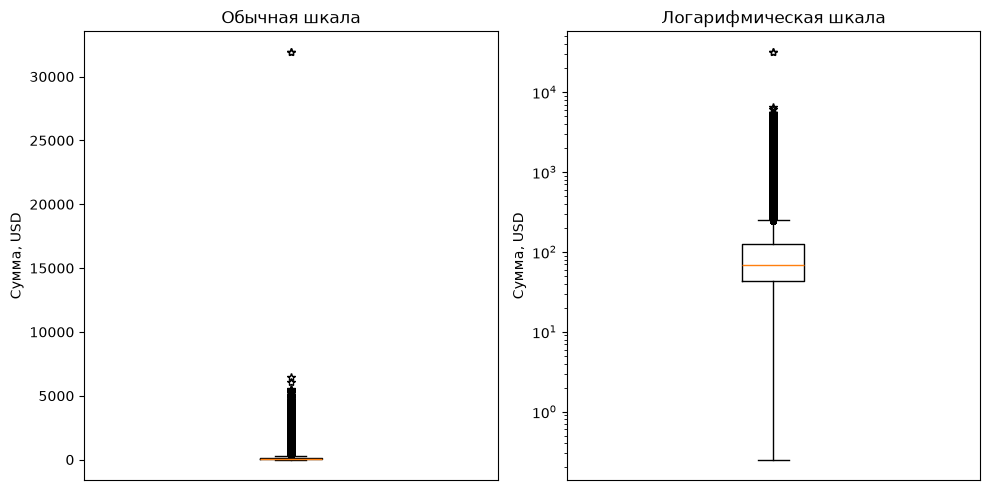

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax in axes:
    ax.boxplot(df["TransactionAmt"], sym="*")
    ax.set(ylabel="Сумма, USD", xticks=[])

axes[0].set_title("Обычная шкала")
axes[1].set_title("Логарифмическая шкала")
axes[1].set_yscale("log")

plt.tight_layout()
plt.show()

За границами IQR находятся 66 482 транзакции (11,26%), в том числе 3 372 мошеннические — 16,32% всех мошеннических транзакций. Удаление этих строк исключило бы заметную часть транзакций.

Даже максимальная сумма `31 937,391 USD` выглядит нормальной величиной транзакции, поэтому сохраняем все строки.